In [1]:
   import pandas as pd

   df = pd.read_excel("../data/default of credit card clients.xls", header=1)
   print(df.shape)
   df.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


# Exploratory Data Analysis
## 1. Initial inspection

In [3]:
# Data types and non-null counts for each column
df.info()

# Missing values per column
print("\nMissing values per column:")
print(df.isnull().sum())

# Duplicate rows (excluding ID, which is always unique)
print("\nDuplicate rows:", df.drop(columns="ID").duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

## 2. Data cleaning

In [4]:
# Rename columns for clarity
df = df.rename(columns={"PAY_0": "PAY_1",
                        "default payment next month": "default"})

# Drop ID (not useful for prediction)
df = df.drop(columns="ID")

# Remove duplicate rows
df = df.drop_duplicates()

# Undocumented categories before cleaning
print("BEFORE")
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE:", df["MARRIAGE"].value_counts().sort_index().to_dict())

# Group undocumented values into 'others'
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

# Check after cleaning
print("\nAFTER")
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE:", df["MARRIAGE"].value_counts().sort_index().to_dict())
print("\nShape:", df.shape)

BEFORE
EDUCATION: {0: 14, 1: 10563, 2: 14019, 3: 4915, 4: 123, 5: 280, 6: 51}
MARRIAGE: {0: 54, 1: 13643, 2: 15945, 3: 323}

AFTER
EDUCATION: {1: 10563, 2: 14019, 3: 4915, 4: 468}
MARRIAGE: {1: 13643, 2: 15945, 3: 377}

Shape: (29965, 24)


## 3. Target variable

         count  percent
default                
0        23335    77.87
1         6630    22.13


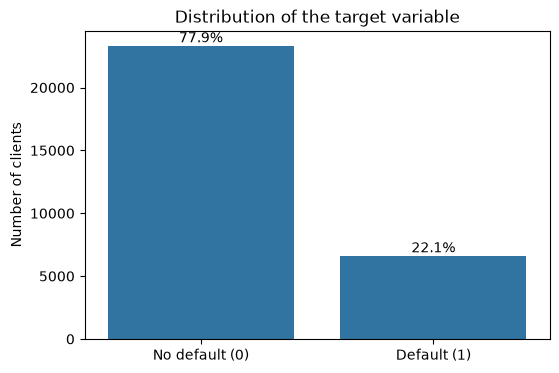

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count and percentage of each class
counts = df["default"].value_counts().sort_index()
percent = df["default"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))

# Bar chart of the target
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="default", data=df)
plt.xticks([0, 1], ["No default (0)", "Default (1)"])
plt.title("Distribution of the target variable")
plt.xlabel("")
plt.ylabel("Number of clients")

# Add percentage labels on top of the bars
ax.bar_label(ax.containers[0], labels=[f"{p:.1f}%" for p in percent])

# Save the figure for the report and slides
plt.savefig("../figures/target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()